# Companion spectrum with KLIP forward modeling

Extracts a point source's contrast spectrum (companion/star flux ratio per IFS
channel) from a coronagraphic ADI sequence with `jighcontrast.jFM.extract_spectrum`
(Pueyo 2016), with uncertainties and channel-to-channel covariance measured on the
data. The PSF calibration is one or two unocculted snapshots, as in a real
observing run.

Calibration follows a real observing sequence without satellite spots: the star
position in the coronagraphic frames is the coronagraph's position on the detector
(`STAR_CENTER`, a fixed number), and the unocculted snapshots only provide the PSF
(each centered on its own peak) and the flux scale.

**To use with your data, edit only the configuration cell.** As committed it runs
on the simulated SCALES HIP 21152 example data. Methods and validation:
[README](../README.md), [validation](../validation/README.md).

In [1]:
import os
import numpy as np

# ---- data (same layout as the scalesETC simulations) --------------------------
DATA_DIR = "."
CORONAGRAPH_FILE = "HIP21152_SCALES_L_3h_coronagraph.fits"  # (n_exp, n_wave, ny, nx)
UNOCCULTED_FILE = "HIP21152_SCALES_L_3h_unocculted.fits"    # unocculted exposure(s), same layout
PSF_SNAPSHOTS = [0, -1]     # unocculted exposures used as the PSF calibration (start and end)
PSF_FLUX_SCALE = 1.0        # coronagraphic / unocculted exposure time (x any ND transmission)
PARANG_FILE = "parallactic_angle_degrees.csv"  # used if the FITS file has no PARANG extension

# ---- instrument ----------------------------------------------------------------
PIXEL_SCALE_MAS = 20.0
TELESCOPE_DIAMETER_M = 10.0
STAR_CENTER = (36.0, 36.0)  # (x, y) of the star behind the coronagraph: the coronagraph's
                            # calibrated position on the detector (0-based, pixel centers).
                            # scalesETC puts it on pixel 54 of its 108x108 frames (36 in the
                            # cropped example files).
DEROT_SIGN = -1             # exposure t is rotated by DEROT_SIGN * parang[t] to put north up
N_KL_MODES = 20
N_JOBS = os.cpu_count()     # worker processes (one per spectral channel at a time)

# ---- the source -------------------------------------------------------------------
COMPANION_SEP_MAS = 390.0
COMPANION_PA_DEG = 217.0    # degrees east of north
TRUTH_FILE = "../validation/data/hip21152b_injected_contrast.csv"  # optional overlay; None to skip
OUTPUT_FILE = "companion_spectrum.fits"

In [2]:
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
            "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(var, "1")

import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from jighcontrast import jFM, jPhot, nan_rot

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "image.origin": "lower"})

# the example data are downloaded on first use (only if the default files are missing)
EXAMPLE_URL = "https://github.com/jordan-stone/jighcontrast/releases/download/example-data/"
for name in (CORONAGRAPH_FILE, UNOCCULTED_FILE):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path) and name.startswith("HIP21152_SCALES"):
        print("downloading", name, "(~100 MB)")
        urllib.request.urlretrieve(EXAMPLE_URL + name, path)

In [3]:
with fits.open(os.path.join(DATA_DIR, CORONAGRAPH_FILE)) as hdul:
    coronagraph = hdul[0].data.astype(float)
    wavelengths = np.asarray(hdul["WAV_MICRONS"].data["wav_microns"], float)
    if "PARANG" in hdul:
        parang = np.asarray(hdul["PARANG"].data["parang_deg"], float)
    else:
        parang = np.loadtxt(os.path.join(DATA_DIR, PARANG_FILE), delimiter=",")
with fits.open(os.path.join(DATA_DIR, UNOCCULTED_FILE)) as hdul:
    unocculted = hdul[0].data.astype(float)[PSF_SNAPSHOTS]

n_exp, n_wave, ny, nx = coronagraph.shape
center = STAR_CENTER
print("coronagraphic sequence:", coronagraph.shape, "| %.2f-%.2f um | rotation %.0f deg"
      % (wavelengths.min(), wavelengths.max(), np.ptp(parang)))
print("PSF calibration: %d unocculted exposure(s)" % len(unocculted))

# Center each snapshot on its own peak (tip/tilt differs from snapshot to snapshot)
# so the PSF model is centered. This uses the snapshots only to build the PSF; the
# star position in the coronagraphic frames is STAR_CENTER.
centered = []
for snapshot in unocculted:
    peak_xy = jPhot.measure_star_centers(snapshot, center)
    centered.append(jPhot.register_channels(snapshot[None], peak_xy, center)[0])
    print("snapshot star position across the band: x %.2f..%.2f, y %.2f..%.2f"
          % (peak_xy[:, 0].min(), peak_xy[:, 0].max(), peak_xy[:, 1].min(), peak_xy[:, 1].max()))
unocculted = np.array(centered)

# Off-axis PSF per channel: defines unit contrast (companion/star flux ratio).
half = int(np.ceil(2 * jFM.resolution_element_pix(wavelengths.max(), TELESCOPE_DIAMETER_M,
                                                  PIXEL_SCALE_MAS)))
psf_stamps = PSF_FLUX_SCALE * jFM.offaxis_psf_stamps(unocculted, center, half=half)
if len(unocculted) > 1:
    flux = unocculted.sum(axis=(2, 3))
    change = flux[-1] / flux[0] - 1
    print("PSF calibration stability, last vs first snapshot: %+.1f%% to %+.1f%% across channels"
          % (100 * change.min(), 100 * change.max()))

coronagraphic sequence: (90, 54, 72, 72) | 2.91-4.14 um | rotation 108 deg
PSF calibration: 2 unocculted exposure(s)
snapshot star position across the band: x 35.99..36.46, y 35.88..36.83
snapshot star position across the band: x 36.00..36.48, y 35.86..36.81
PSF calibration stability, last vs first snapshot: -0.7% to +0.1% across channels


## Geometry check

A quick classical-ADI image (channels averaged, median subtracted, derotated). The
companion should sit in the circle; if it does not, check `DEROT_SIGN`, the
position-angle convention and the parallactic angles before going further.

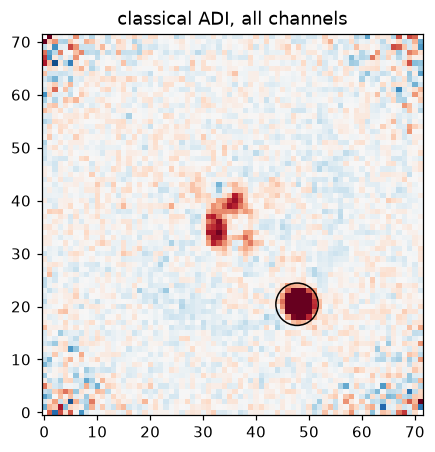

In [4]:
sep_pix = COMPANION_SEP_MAS / PIXEL_SCALE_MAS
src_x = center[0] - sep_pix * np.sin(np.deg2rad(COMPANION_PA_DEG))
src_y = center[1] + sep_pix * np.cos(np.deg2rad(COMPANION_PA_DEG))

broadband = coronagraph.mean(axis=1)
residual = broadband - np.median(broadband, axis=0)
import warnings
with warnings.catch_warnings():          # frame corners are empty after rotation
    warnings.simplefilter("ignore", RuntimeWarning)
    adi = np.nanmean([nan_rot.nan_rot(r, DEROT_SIGN * q, center, out_size=(ny, nx), pivot=True)
                      for r, q in zip(residual, parang)], axis=0)
yy, xx = np.indices(adi.shape)
outside_core = np.hypot(xx - center[0], yy - center[1]) > 0.5 * sep_pix
vmax = np.nanpercentile(np.abs(adi[outside_core]), 99.5)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(adi, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax.add_patch(plt.Circle((src_x, src_y), 4, fill=False, color="k"))
ax.set_title("classical ADI, all channels")
plt.show()

## Extraction

`extract_spectrum` reduces each channel with KLIP (references from the same
channel), forward-models how KLIP processes a source at the given position, and
fits the spectrum. A bright source is refined by subtracting the current estimate
and re-fitting. Errors come from applying the same estimator at empty positions
around the ring at the source's separation.

In [5]:
result = jFM.extract_spectrum(
    coronagraph, None, parang, wavelengths, center, sep_pix, COMPANION_PA_DEG,
    TELESCOPE_DIAMETER_M, PIXEL_SCALE_MAS, psf_stamps=psf_stamps, npca=N_KL_MODES,
    derot_sign=DEROT_SIGN, n_jobs=N_JOBS, verbose=False)

spectrum, sigma = result["spectrum"], result["sigma"]
bb = result["broadband"]
print("band-averaged contrast %.3e +/- %.1e  (S/N %.1f; %d independent noise positions)"
      % (bb["contrast"], bb["sigma"], bb["snr"], result["n_ring"]))
# dlam / mixing >~ 0.1: the source is too bright for one first-order pass;
# extract_spectrum then refines it (n_iter passes).
print("refinement passes: %d; first-order diagnostics max dlam %.2f, mixing %.2f"
      % (result["n_iter"], result["dlam_fit"].max(), result["mixing_fit"].max()))
if len(result["unstable_channels"]):
    print("channels still moving > 1 sigma between passes:",
          wavelengths[result["unstable_channels"]].round(3))

band-averaged contrast 1.351e-04 +/- 2.2e-06  (S/N 61.0; 23 independent noise positions)
refinement passes: 2; first-order diagnostics max dlam 1.55, mixing 1.47


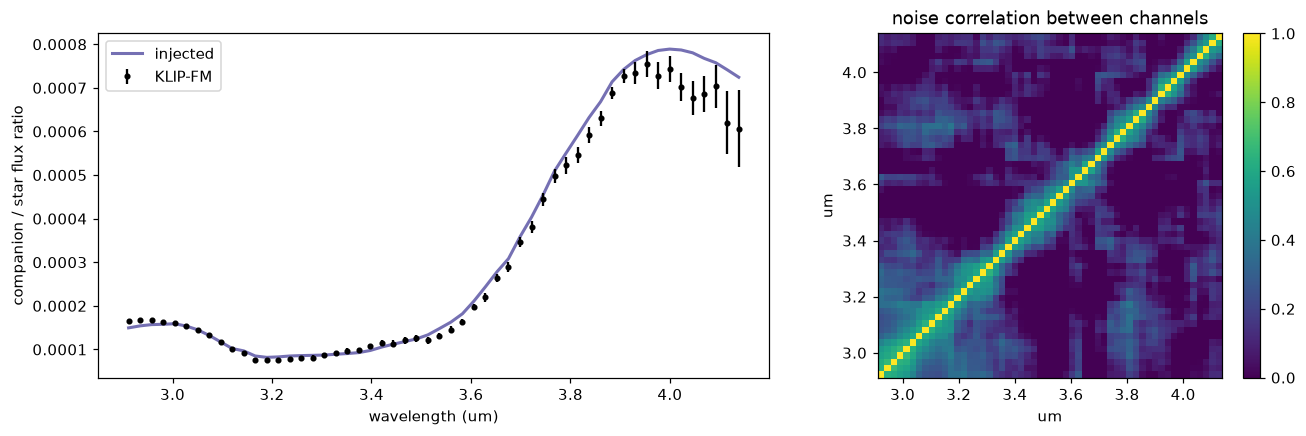

In [6]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw=dict(width_ratios=[1.6, 1]))
if TRUTH_FILE and os.path.exists(TRUTH_FILE):
    ax.plot(wavelengths, np.loadtxt(TRUTH_FILE, delimiter=",")[:, 1], "-", color="#7570b3",
            lw=2, label="injected")
ax.errorbar(wavelengths, spectrum, sigma, fmt="o", ms=3, color="k", label="KLIP-FM")
ax.set(xlabel="wavelength (um)", ylabel="companion / star flux ratio")
ax.legend()
im = ax2.imshow(result["corr"], vmin=0, vmax=1, cmap="viridis",
                extent=[wavelengths[0], wavelengths[-1], wavelengths[0], wavelengths[-1]])
ax2.set(title="noise correlation between channels", xlabel="um", ylabel="um")
plt.colorbar(im, ax=ax2, fraction=0.046)
plt.tight_layout()
plt.show()

In the simulated example data the star's position drifts by about a pixel across
the band -- an artifact of the simulator, which rescales its PSF with wavelength
about the array edge rather than the PSF center. With one fixed `STAR_CENTER` that
drift tilts the extracted spectrum by several percent toward the band edges. Real
data are expected to drift far less (atmospheric dispersion for this target from
Mauna Kea: ~0.1 pixel across the band; see the validation notes).

## Save

The spectrum, its 1-sigma errors and the full covariance (use the covariance, not
just the error bars, when fitting models: channels are correlated).

In [7]:
table = fits.BinTableHDU.from_columns([
    fits.Column("wavelength_um", "D", array=wavelengths),
    fits.Column("contrast", "D", array=spectrum),
    fits.Column("sigma", "D", array=sigma)], name="SPECTRUM")
header = fits.Header()
header["SEP_MAS"], header["PA_DEG"] = COMPANION_SEP_MAS, COMPANION_PA_DEG
header["NKL"], header["NRING"] = N_KL_MODES, result["n_ring"]
header["BBCONTR"], header["BBSIGMA"] = bb["contrast"], bb["sigma"]
fits.HDUList([fits.PrimaryHDU(header=header), table,
              fits.ImageHDU(result["cov"], name="COVARIANCE")]).writeto(OUTPUT_FILE, overwrite=True)
print("wrote", OUTPUT_FILE)

wrote companion_spectrum.fits
